<a href="https://colab.research.google.com/github/i5head/Applied-Deep-Learning/blob/main/Turorial3_fashionmnist_Applied_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.model_selection import train_test_split
import seaborn as sns
from tensorflow.keras.utils import to_categorical


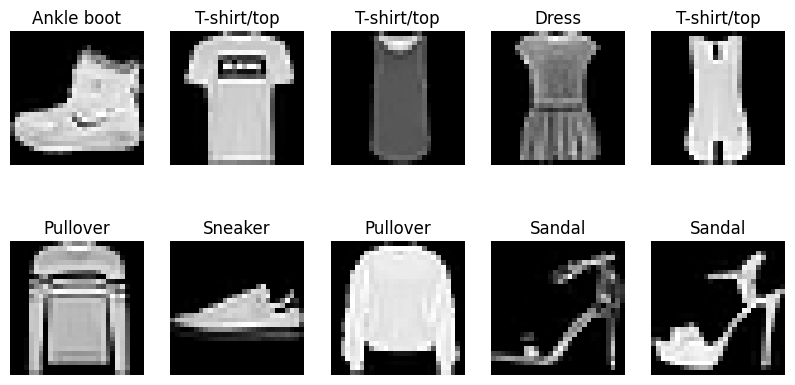

In [52]:
# 1. Load the Fashion-MNIST dataset
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Display a few sample images
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="grey")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")
plt.show()

In [53]:
# 2. Normalize the data to [0, 1]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add a channel dimension (since CNN expects 4D input)
x_train_full = np.expand_dims(x_train_full, -1)
x_test = np.expand_dims(x_test, -1)

print(x_train_full.shape)


(60000, 28, 28, 1)


In [54]:
# 3. Split into training (50%), validation (25%), test (25%)

x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full, test_size=0.5, random_state=42)
x_val, x_train, y_val, y_train = train_test_split(x_train, y_train, test_size=0.5, random_state=42)

# double splitt of the data set into 3 different kind of sets

print(x_train.shape)
print(x_val.shape)
print(x_test.shape)

(15000, 28, 28, 1)
(15000, 28, 28, 1)
(10000, 28, 28, 1)


In [55]:
# 3.1 Convert the labels to a one-hot encoding
print(y_train.shape)
print(x_train.shape)


(15000,)
(15000, 28, 28, 1)


In [56]:
# 4. Define a CNN classifier
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', input_shape=(28, 28, 1)), # Convolution of the pixels
    tf.keras.layers.BatchNormalization(), # this is a way to normalise the batches
    tf.keras.layers.Activation('relu'), # Activation function in order to have more complex problems - introduces non-linearity
    tf.keras.layers.MaxPooling2D((2, 2)), # Looks at 4 neibourghing values - keeping only the maximum

    # do it again for more complexity
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),


    tf.keras.layers.Flatten(), # takes the 3-dim array and puts it into a single array
    tf.keras.layers.Dense(128, activation='relu'), # neurons that are all connected with the inputs --> these are the parameters the model learns
    tf.keras.layers.Dense(10, activation='softmax') #this produces the outputlayer that is needed (10 different pictures) --> needs softmax since it is a ten-class-problem
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [57]:
# 4.1 Good practise is to show the layers of the model
print(model.summary())

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 26, 26, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 11, 11, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 11, 11, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,810 (425.04 KB)

 Trainable params: 108,714 (424.66 KB)

 Non-trainable params: 96 (384.00 B)

None


In [58]:
print("x shape:", x_train.shape)
print("y shape:", y_train.shape)
print("Model output:", model.output_shape)

x shape: (15000, 28, 28, 1)
y shape: (15000,)
Model output: (None, 10)


In [59]:
# 5. Train the model
history = model.fit(x_train, y_train, epochs=10, validation_data=(x_val, y_val))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - accuracy: 0.8025 - loss: 0.5523 - val_accuracy: 0.8030 - val_loss: 0.6724
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 31s 67ms/step - accuracy: 0.8678 - loss: 0.3560 - val_accuracy: 0.8238 - val_loss: 0.4763
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - accuracy: 0.8921 - loss: 0.2880 - val_accuracy: 0.8627 - val_loss: 0.3838
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 35s 73ms/step - accuracy: 0.9099 - loss: 0.2435 - val_accuracy: 0.8717 - val_loss: 0.3644
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.9267 - loss: 0.2008 - val_accuracy: 0.8688 - val_loss: 0.4149
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - accuracy: 0.9305 - loss: 0.1842 - val_accuracy: 0.8806 - val_loss: 0.3819
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 34s 40ms/step - accuracy: 0.9395 - loss: 0.1603 - val_accuracy: 0.8518 - val_loss: 0.4932
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 29s 59ms/step - accuracy: 0.9525 - loss: 0.1291 - 

In [60]:
# 5.1 Evaluate the model on the test data
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'\nTest accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8709 - loss: 0.4947

Test accuracy: 0.8708999752998352


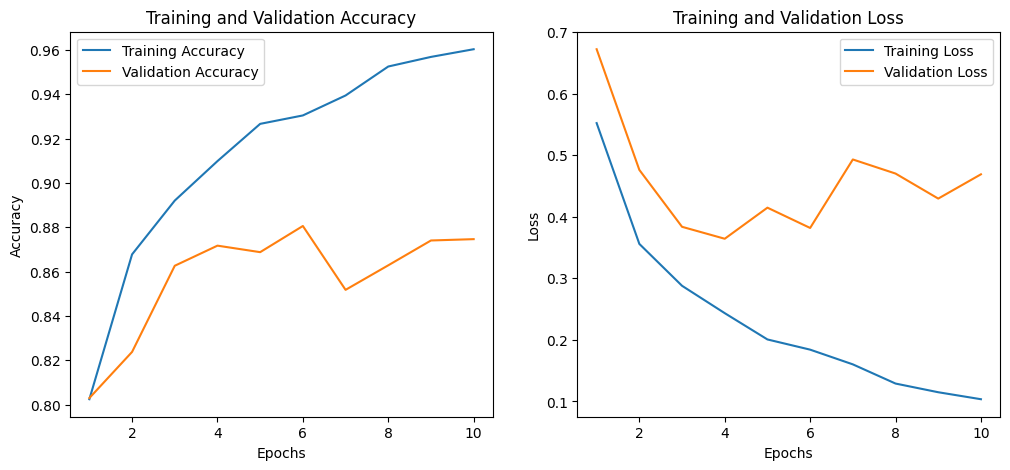

In [61]:
# 6. Plot learning curves
# Plot training & validation accuracy and loss, COPY THIS
def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot training & validation accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Training Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot training & validation loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Training Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()


plot_training_history(history)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


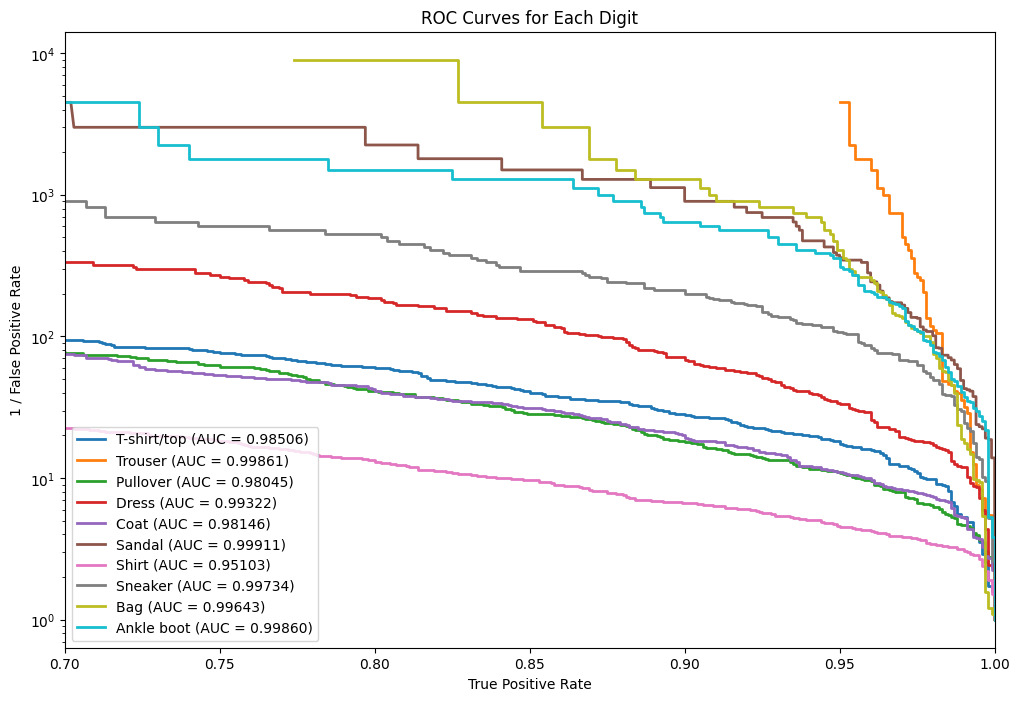

In [73]:
# 7. ROC Curves (one-vs-all)

from sklearn.preprocessing import label_binarize

# Generate ROC curves for each digit (one-vs-rest)

def plot_roc_curves(y_true, y_pred):

    y_true_bin = label_binarize(y_true, classes=np.arange(len(class_names)))

    plt.figure(figsize=(12, 8))
    colors = plt.get_cmap('tab10')

    for i in range(len(class_names)):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred[:, i]) # false positive rate and true positive rate - give true label and the model prediciton

        # Compute the standard ROC AUC before any transformation
        roc_auc = auc(fpr, tpr)

        # Exclude zero FPR values to avoid division by zero
        mask = fpr > 0

        plt.plot(
            tpr[mask],
            1.0 / fpr[mask],
            color=colors(i),
            lw=2,
            label=f"{class_names[i]} (AUC = {roc_auc:.5f})"
        )

    plt.yscale("log")
    plt.xlim([0.7, 1.0])
    plt.ylabel('1 / False Positive Rate')
    plt.xlabel('True Positive Rate')
    plt.title('ROC Curves for Each Digit')
    plt.legend(loc='lower left')
    plt.show()


plot_roc_curves(y_test, model.predict(x_test))


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step


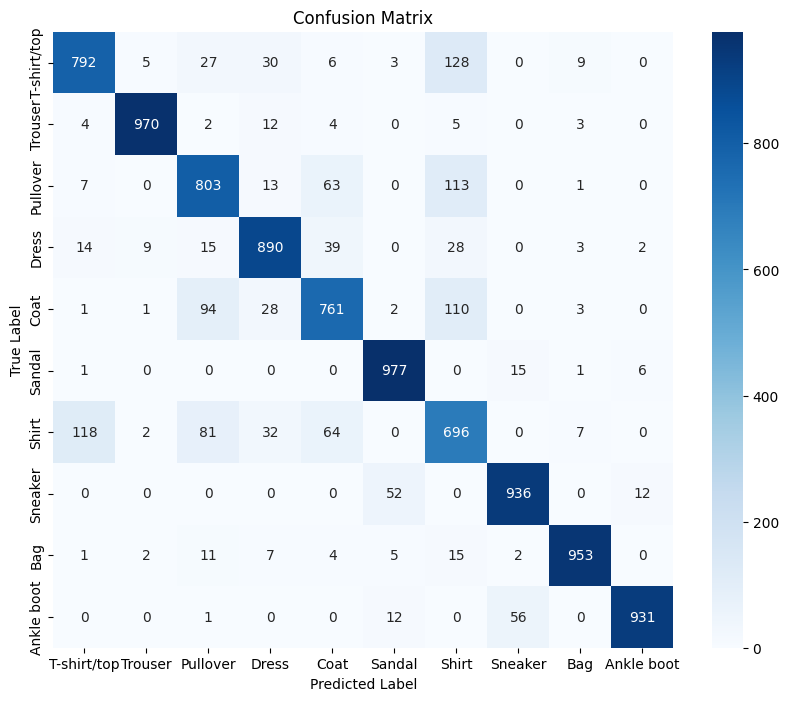

In [79]:
# 8. Confusion Matrix
def plot_confusion_matrix(y_true, y_pred):
    y_pred_classes = np.argmax(y_pred, axis=1)
    cm = confusion_matrix(y_true, y_pred_classes)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels= class_names, yticklabels=class_names)

    plt.title(class_names[i])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_confusion_matrix(y_test, model.predict(x_test))